<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Hysteresis_Loop_CoFeB_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

In [ ]:
!uv pip install mumaxplus matplotlib numpy

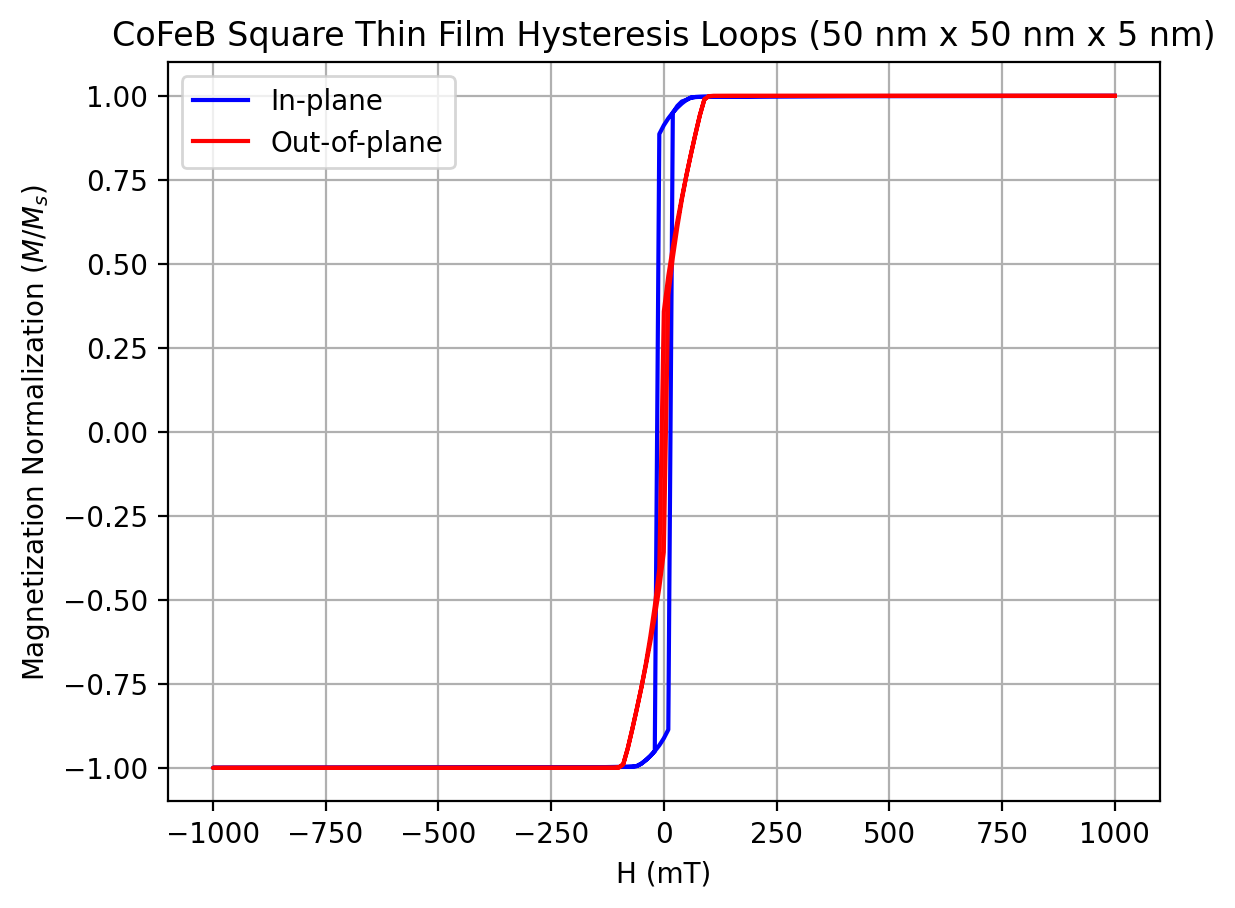

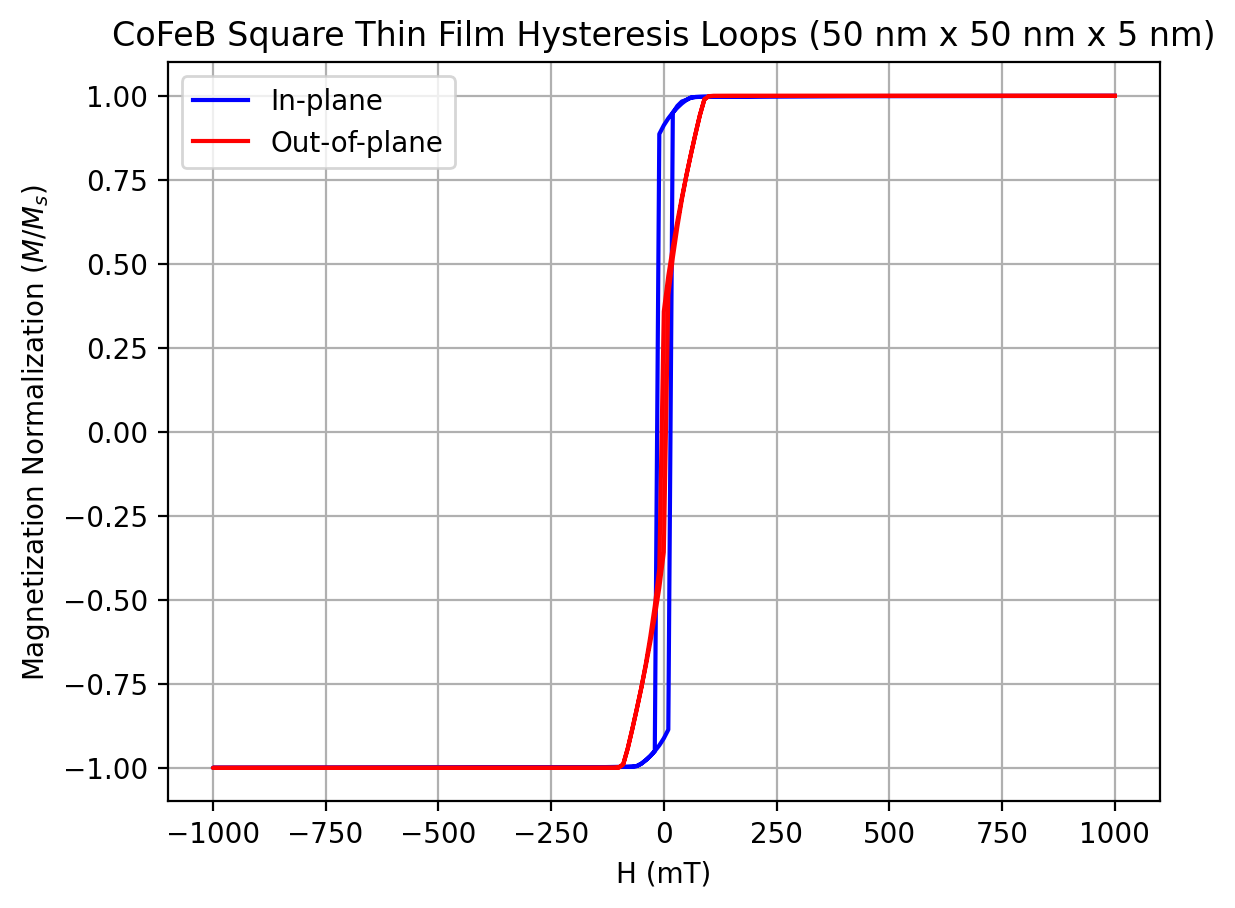

In [3]:
"""This script computes overlapping in-plane and out-of-plane CoFeB hysteresis loops.

The simulation models a 50 nm x 50 nm x 5 nm CoFeB square thin film discretized
into 2.5 nm cubic cells using native mumaxplus syntax.
"""

import matplotlib.pyplot as plt
from mumaxplus import Ferromagnet
from mumaxplus import Grid
from mumaxplus import World
import numpy as np

plt.rcParams['figure.dpi'] = 200

world = World(cellsize=(2.5e-9, 2.5e-9, 2.5e-9))
magnet = Ferromagnet(world, Grid((20, 20, 2)))

magnet.msat = 9.57e5
magnet.aex = 13e-12
magnet.ku1 = 3.86e5
magnet.anisU = (0, 0, 1)
magnet.alpha = 0.05

b_max = 1.0
b_step = 0.01
b_array = np.concatenate((
    np.arange(b_max, -b_max - b_step * 0.5, -b_step),
    np.arange(-b_max + b_step, b_max + b_step * 0.5, b_step),
))

magnet.magnetization = (1.0, 0.05, 0.05)
world.bias_magnetic_field = (b_max, 0.0, 5e-4)
magnet.relax()

mx_in_plane = []
for b_ext in b_array:
    world.bias_magnetic_field = (b_ext, 0.0, 5e-4)
    magnet.minimize()
    mx_in_plane.append(magnet.magnetization.average()[0])

magnet.magnetization = (0.05, 0.05, 1.0)
world.bias_magnetic_field = (5e-4, 0.0, b_max)
magnet.relax()

mz_out_of_plane = []
for b_ext in b_array:
    world.bias_magnetic_field = (5e-4, 0.0, b_ext)
    magnet.minimize()
    mz_out_of_plane.append(magnet.magnetization.average()[2])

b_mt = b_array * 1e3
plt.plot(b_mt, mx_in_plane, color='blue', linewidth=1.5, label='In-plane')
plt.plot(b_mt, mz_out_of_plane, color='red', linewidth=1.5, label='Out-of-plane')
plt.xlabel('H (mT)')
plt.ylabel('Magnetization Normalization ($M/M_s$)')
plt.title('CoFeB Square Thin Film Hysteresis Loops (50 nm x 50 nm x 5 nm)')
plt.grid(True)
plt.legend()
plt.show()